In [3]:
import numpy as np
from scipy.stats import norm
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

### Parametri riportati dal PDG
Upsilon(1S) : 9460.40 +- 120 MeV\
Upsilon(2S) : 10023.4 +- 127 MeV\
Upsilon(3S) : 10355.1 +- 131 MeV


In [12]:
def gauss(x, mu, sigma):
    k = 1/( np.sqrt(2*np.pi) * sigma )
    expon = np.exp( -(x-mu)**2 /(2 * sigma**2) )
    return k * expon

def poly4(x, a4, a3, a2, a1, a0):
    x = x-8
    return (a4*x**4 + a3*x**3 + a2*x**2 + a1*x + a0)/1000

### Costruzione del modello
La seguente cella contiene il modello "ideale", pulito, senza fluttuazioni statistiche, costituito da background + segnale.

In [24]:
# parametri della collaborazione ATLAS
delta_bin = 50/1000  # GeV
Lum_int   = 1.8      # fb^-1
eps       = 0.2      # parametro di efficienza
edges   = np.arange(8, 11.5 + delta_bin, delta_bin)
x_bin   = 0.5 * (edges[:-1] + edges[1:])

x_fit   = np.linspace(8, 11.5, 5000)


# Lavoro in GeV
mu1 = 9460.40 / 1000
mu2 = 10023.4 / 1000
mu3 = 10355.1 / 1000

std1 = 120 / 1000
std2 = 127 / 1000
std3 = 131 / 1000


# Sezioni d'urto fornite in nb, da portare in fb
sigma1 = 1.890 * 1e6
sigma2 = 0.601 * 1e6
sigma3 = 0.304 * 1e6


# Costruisco le distribuzioni dei conteggi, scalando le gaussiane (pdf) con N
# N_i = L_int * sigma_i * eps
resonance1 = lambda x: gauss(x, mu1, std1) * Lum_int * sigma1 * eps
resonance2 = lambda x: gauss(x, mu2, std2) * Lum_int * sigma2 * eps
resonance3 = lambda x: gauss(x, mu3, std3) * Lum_int * sigma3 * eps

f1 = resonance1(x_fit)
f2 = resonance2(x_fit)
f3 = resonance3(x_fit)

# Costruisco un background random ad hoc (costruito su desmos)
a0 = 300
a1 = -10
a2 = 4.5
a3 = -31
a4 = 9
background_model = lambda x: poly4(x, a4, a3, a2, a1, a0) * Lum_int * (1e7 - sigma1 - sigma2 - sigma3) * eps
bkg = background_model(x_fit)

### Generazione dei dati simulati
La seguente cella costruisce un sample con fluttuazioni statistiche poissoniane in ciascun bin.\
La media poissoniana di ciascun bin è data dal valore (in quel bin) predetto dal modello ideale.\
Osservazione: l'ordine di grandezza caratteristico degli eventi ottenuti è 10^6.\
Con questa statistica, è impossibile osservare fluttuazioni poissoniane considerevoli.\
Dato che lo scopo è fittare il modello da dati "simulati", voglio gonfiare artificialmente le fluttuazioni.\
Per fare ciò scalo il numero di eventi con un fattore di frazionamento, faccio le estrazioni poissoniane, e poi scalo nel verso opposto.

In [68]:
# costruisco i conteggi per ciascun bin come estrazioni poissoniane rispetto al modello ideale
f = 1e-4 # fattore di frazionamento dei dati
binned_model = (background_model(x_bin) + resonance1(x_bin) + resonance2(x_bin) + resonance3(x_bin)) * f
data = [np.random.poisson(n) / f for n in binned_model]
data = np.asarray(data)

# associo l'errore come puramente statistico (radice dei conteggi, errori poissoniani)
err_data = np.sqrt(binned_model) / f

### Plotting Section

<function matplotlib.pyplot.show(close=None, block=None)>

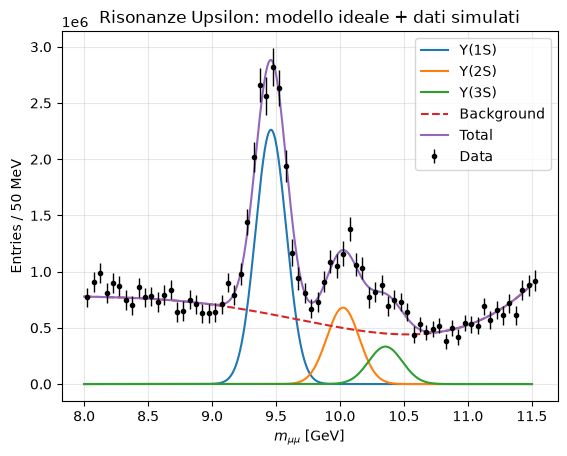

In [69]:
fig, ax = plt.subplots()

# Plot del modello:

# Risonanze
ax.plot(x_fit, f1, label="Y(1S)")
ax.plot(x_fit, f2, label="Y(2S)")
ax.plot(x_fit, f3, label="Y(3S)")

# Background
ax.plot(x_fit, bkg, "--", label="Background")

# Spettro totale atteso
ax.plot(x_fit, f1 + f2 + f3 + bkg, label="Total")


# Plot dei dati
ax.errorbar(x_bin, data, yerr=err_data,
            fmt='o', color='k', ms=3, capsize=0, elinewidth=1,
            label='Data')


# Dettagli estetici
ax.set_title("Risonanze Upsilon: modello ideale + dati simulati")
ax.set_xlabel(r"$m_{{\mu \mu}}$ [GeV]")
ax.set_ylabel("Entries / 50 MeV")
ax.grid(alpha=0.3)
ax.legend()

plt.show

### Fitting section
Adesso lo scopo è fittare i dati simulati con il modello a 5 + 2 + 2 + 2 parametri (bkg polinomiale di grado 4, 3 risonanze gaussiane).\
Alcuni parametri sono stati considerati come noti, in particolare le sezioni d'urto, che nell'andamento funzionale entrano come ampiezze delle risonanze.\
Suppongo esistano dipendenze dalla massa che riducono la dimensionalità del problema, e che lasciare liberi 3 parametri in più sia troppo permissivo.

In [72]:
from iminuit import Minuit
from iminuit.cost import LeastSquares

# Nel modello, i seguenti parametri sono considerati noti:
# Luminosità integrata: Lum_int
# Efficienza:           eps
# Sezioni d'urto:       sigma1, sigma2, sigma3

def model_function(x, a4, a3, a2, a1, a0, mu1, std1, sigma1, mu2, std2, sigma2, mu3, std3, sigma3):
    f_bkg   = poly4(x, a4, a3, a2, a1, a0) * Lum_int * (1e7 - sigma1 - sigma2 - sigma3) * eps
    f_res_1 = gauss(x, mu1, std1) * Lum_int * sigma1 * eps
    f_res_2 = gauss(x, mu2, std2) * Lum_int * sigma2 * eps
    f_res_3 = gauss(x, mu3, std3) * Lum_int * sigma3 * eps
    return f_bkg + f_res_1 + f_res_2 + f_res_3

# Starting parameters
p0 = [0, 0, 0, 0, 300]      # bkg
p1 = [9.5,  0.5, 1.5*1e6]   # Y(1S)
p2 = [10,   0.5, 0.5*1e6]   # Y(2S)
p3 = [10.4, 0.5, 0.5*1e6]   # Y(3S)


mask = np.where(data > 0)[0]
least_squares = LeastSquares(x_bin[mask], data[mask], err_data[mask], model_function)
m = Minuit(least_squares, *p0, *p1, *p2, *p3)

m.limits["mu1"] = (9.3, 9.6)
m.limits["mu2"] = (9.8, 10.2)
m.limits["mu3"] = (10.3, 10.5)

m.limits["sigma1"] = (0, None)
m.limits["sigma2"] = (0, None)
m.limits["sigma3"] = (0, None)

m.values["sigma1"] = 1.890 * 1e6
m.values["sigma2"] = 0.601 * 1e6
m.values["sigma3"] = 0.304 * 1e6

m.fixed["sigma1"] = True
m.fixed["sigma2"] = True
m.fixed["sigma3"] = True

m.migrad()
m.hesse()
m.minos()
popt = m.values
cov  = m.covariance

print(m)

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 47.68 (χ²/ndof = 0.8)      │             Nfcn = 4326              │
│ EDM = 8.67e-05 (Goal: 0.0002)    │            time = 0.5 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬────

M1 = 9.4604 GeV
M2 = 10.0234 GeV
M3 = 10.3551 GeV

M1 = 9.4475 +0.005 -0.005 GeV
M2 = 10.0306 +0.013 -0.013 GeV
M3 = 10.3608 +0.029 -0.031 GeV



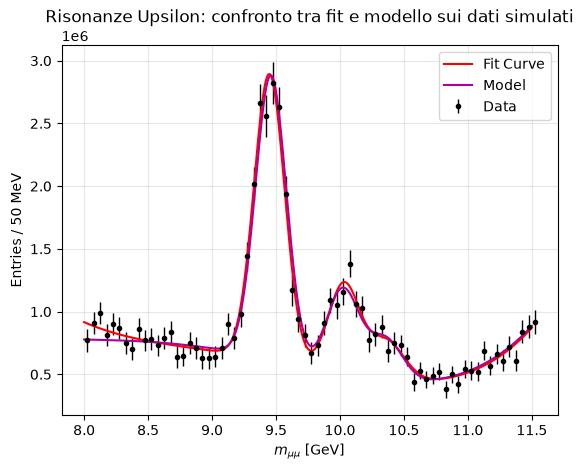

In [78]:
fig, ax = plt.subplots()

# Plot dei dati
ax.errorbar(x_bin, data, yerr=err_data,
            fmt='o', color='k', ms=3, capsize=0, elinewidth=1,
            label='Data')

# Plot del fit
ax.plot(x_fit, model_function(x_fit, *popt), color="red", label="Fit Curve")

# Plot del modello totale
ax.plot(x_fit, f1 + f2 + f3 + bkg, color="#ad009f", label="Model")


# Dettagli estetici
ax.set_title("Risonanze Upsilon: confronto tra fit e modello sui dati simulati")
ax.set_xlabel(r"$m_{{\mu \mu}}$ [GeV]")
ax.set_ylabel("Entries / 50 MeV")
ax.grid(alpha=0.3)
ax.legend()

plt.show

# Valori reali delle masse delle risonanze
print(f"M1 = {mu1:.4f} GeV")
print(f"M2 = {mu2:.4f} GeV")
print(f"M3 = {mu3:.4f} GeV")
print("")

# Valori delle masse delle risonanze trovati dal fit sulla simulazione
m_err_1    = m.merrors['mu1']
err_high_1 = m_err_1.upper
err_low_1  = m_err_1.lower

m_err_2    = m.merrors['mu2']
err_high_2 = m_err_2.upper
err_low_2  = m_err_2.lower

m_err_3    = m.merrors['mu3']
err_high_3 = m_err_3.upper
err_low_3  = m_err_3.lower

print(f"M1 = {m.values['mu1']:.4f} +{err_high_1:.3f} {err_low_1:.3f} GeV")
print(f"M2 = {m.values['mu2']:.4f} +{err_high_2:.3f} {err_low_2:.3f} GeV")
print(f"M3 = {m.values['mu3']:.4f} +{err_high_3:.3f} {err_low_3:.3f} GeV")
print("")

### Commenti finali
Il codice è stato scritto in autonomia, a meno di alcuni dettagli realizzati tramite IA (_Claude_, di Anthropic):
- L'aggiunta del fattore eps di efficienza è stato proposto dall'IA come giustificazione al distacco di circa un ordine di grandezza tra i valori caratteristici presenti nel plot di ATLAS, e i valori ricreati con il modello e i parametri indicati.
- x_bin e x_fit erano stati definiti con np.arange(...); tuttavia l'IA ha proposto una miglioria con le definizioni attualmente presenti.
- L'idea dello scaling tramite il parametro f è stato proposto dall'IA.

Una possibile miglioria, che riservo per il futuro, è l'utilizzo di altre funzioni costo di minuit, tra cui quelle viste a lezione (BinnedNLL, UnbinnedNLL).